# Notebook 55 — Autoencoders and latent spaces

This notebook introduces deterministic autoencoders before adding the probabilistic machinery of a variational autoencoder. We will compress small binary images into a low-dimensional latent code, reconstruct them, inspect the learned latent space, and test what happens when we decode arbitrary latent points.

## Learning goals

- distinguish an encoder, latent code, and decoder;
- understand the role of a bottleneck;
- train with a reconstruction objective;
- visualize reconstructions and a two-dimensional latent space;
- interpolate between encoded examples;
- explain why a deterministic autoencoder is not automatically a generative model.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")

print("device:", DEVICE)

device: mps


## 1. From input to reconstruction

An autoencoder contains two learned mappings:

~~~text
image x -> encoder -> latent code z -> decoder -> reconstruction x_hat
~~~

The encoder compresses the input into a smaller representation. The decoder must reconstruct the input using only that representation. If the latent code has much lower dimension than the input, it forms an information bottleneck and encourages the model to preserve useful structure rather than every independent input coordinate.

A bottleneck does not guarantee meaningful features by itself. If the network is too powerful, the latent width too large, or the data too simple, the model may learn an unhelpful near-copying strategy.

## 2. Synthetic binary images

We reuse the visual idea from the [autoregressive notebook](./54_autoregressive_models_and_exact_likelihood.ipynb): horizontal bars, vertical bars, crosses, and rectangular borders with small random pixel noise. The labels are retained only for coloring the latent-space plot; the autoencoder never receives them during training.

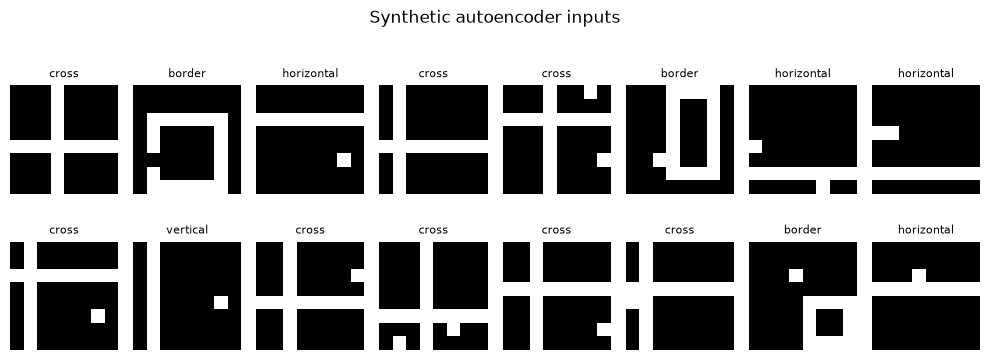

In [3]:
SHAPE_NAMES = ("horizontal", "vertical", "cross", "border")


def make_binary_shape_images(number_images, image_size=8, noise_probability=0.02, seed=0):
    generator = torch.Generator().manual_seed(seed)
    images = torch.zeros(number_images, image_size, image_size)
    labels = torch.randint(0, 4, (number_images,), generator=generator)

    for index, label in enumerate(labels.tolist()):
        row = int(torch.randint(1, image_size - 1, (), generator=generator))
        column = int(torch.randint(1, image_size - 1, (), generator=generator))
        if label == 0:
            images[index, row, :] = 1.0
        elif label == 1:
            images[index, :, column] = 1.0
        elif label == 2:
            images[index, row, :] = 1.0
            images[index, :, column] = 1.0
        else:
            top = int(torch.randint(0, image_size - 3, (), generator=generator))
            left = int(torch.randint(0, image_size - 3, (), generator=generator))
            bottom = int(torch.randint(top + 2, image_size, (), generator=generator))
            right = int(torch.randint(left + 2, image_size, (), generator=generator))
            images[index, top, left : right + 1] = 1.0
            images[index, bottom, left : right + 1] = 1.0
            images[index, top : bottom + 1, left] = 1.0
            images[index, top : bottom + 1, right] = 1.0

    noise = torch.rand(number_images, image_size, image_size, generator=generator)
    images = torch.where(noise < noise_probability, 1.0 - images, images)
    return images, labels


train_images, train_labels = make_binary_shape_images(4000, seed=SEED)
evaluation_images, evaluation_labels = make_binary_shape_images(1000, seed=SEED + 1)

fig, axes = plt.subplots(2, 8, figsize=(10, 4))
for axis, image, label in zip(axes.flat, train_images[:16], train_labels[:16]):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.set_title(SHAPE_NAMES[int(label)], fontsize=8)
    axis.axis("off")
plt.suptitle("Synthetic autoencoder inputs")
plt.tight_layout()
plt.show()

## 3. Encoder, bottleneck, and decoder

Each image contains 64 pixel values. The encoder maps those values through a hidden layer into a two-dimensional latent code. Two dimensions create a severe bottleneck, but they also let us draw the complete latent representation on a scatter plot.

The decoder maps the two latent values back to 64 output logits. These logits are not yet pixel probabilities; applying sigmoid converts each one into a value between zero and one.

### Exercise 1 — Complete the autoencoder

In [4]:
class TinyAutoencoder(nn.Module):
    def __init__(self, image_size=8, hidden_dim=32, latent_dim=2):
        super().__init__()
        self.image_size = image_size
        self.input_dim = image_size * image_size
        self.latent_dim = latent_dim
        self.encoder_hidden = nn.Linear(self.input_dim, hidden_dim)
        self.encoder_output = nn.Linear(hidden_dim, latent_dim)
        self.decoder_hidden = nn.Linear(latent_dim, hidden_dim)
        self.decoder_output = nn.Linear(hidden_dim, self.input_dim)

    def encode(self, images):
        # flatten each image, apply encoder_hidden + ReLU, then encoder_output.
        x_flat = images.reshape(images.shape[0], -1)
        x = F.relu(self.encoder_hidden(x_flat))
        return self.encoder_output(x)

    def decode(self, latent_codes):
        # apply decoder_hidden + ReLU and decoder_output.
        # Restore the output logits to shape (N, H, W).
        x = F.relu(self.decoder_hidden(latent_codes))
        x = self.decoder_output(x)
        return x.reshape(x.shape[0], self.image_size, self.image_size)

    def forward(self, images):
        # encode and then decode the images.
        latent = self.encode(images)
        return self.decode(latent)


torch.manual_seed(SEED)
shape_model = TinyAutoencoder()
toy_images = train_images[:5]
toy_codes = shape_model.encode(toy_images)
toy_logits = shape_model(toy_images)
assert toy_codes.shape == (5, 2)
assert toy_logits.shape == (5, 8, 8)

## 4. Reconstruction objective

Every target pixel is binary, so we model it with a Bernoulli distribution. The decoder produces one logit s for each pixel, and sigmoid gives the predicted probability p = sigmoid(s). Binary cross-entropy is the negative log-likelihood of the observed binary pixel:

$$
\ell(x,s)=-x\log\sigma(s)-(1-x)\log(1-\sigma(s)).
$$

PyTorch's binary_cross_entropy_with_logits combines sigmoid and binary cross-entropy in one numerically stable operation. The mean reduction below averages across both images and pixels.

### Exercise 2 — Implement reconstruction loss

In [6]:
def binary_reconstruction_loss(reconstruction_logits, targets, reduction="mean"):
    if reconstruction_logits.shape != targets.shape:
        raise ValueError("reconstruction_logits and targets must have equal shapes")
    # return stable binary cross-entropy from logits.
    return F.binary_cross_entropy_with_logits(reconstruction_logits, targets, reduction=reduction)


toy_loss = binary_reconstruction_loss(toy_logits, toy_images)
expected_loss = F.binary_cross_entropy_with_logits(toy_logits, toy_images)
torch.testing.assert_close(toy_loss, expected_loss)

## 5. One optimization step

Training has the familiar sequence: clear old gradients, run the forward pass, calculate reconstruction loss, backpropagate, and update the parameters. Both encoder and decoder learn from the same reconstruction loss.

### Exercise 3 — Complete one training step

In [9]:
def autoencoder_training_step(model, images, optimizer):
    model.train()
    images = images.to(next(model.parameters()).device)
    # clear gradients.
    optimizer.zero_grad()
    # reconstruct images and calculate the loss.
    loss = binary_reconstruction_loss(model(images), images)
    # backpropagate and update the parameters.
    loss.backward()
    optimizer.step()
    return float(loss.item())


step_model = TinyAutoencoder().to(DEVICE)
step_optimizer = torch.optim.Adam(step_model.parameters(), lr=1e-3)
before = step_model.encoder_hidden.weight.detach().clone()
step_loss = autoencoder_training_step(step_model, train_images[:64], step_optimizer)
after = step_model.encoder_hidden.weight.detach()
assert np.isfinite(step_loss)
assert not torch.equal(before, after)

## 6. Train the autoencoder

The complete loop repeats the same step over mini-batches. We will record mean reconstruction loss per image. Because each image contains the same number of pixels, this is suitable for comparing epochs in this experiment.

### Exercise 4 — Complete the epoch loop

epoch  1: reconstruction loss = 0.6554
epoch  5: reconstruction loss = 0.4581
epoch 10: reconstruction loss = 0.3995
epoch 15: reconstruction loss = 0.3704
epoch 20: reconstruction loss = 0.3451
epoch 25: reconstruction loss = 0.3271


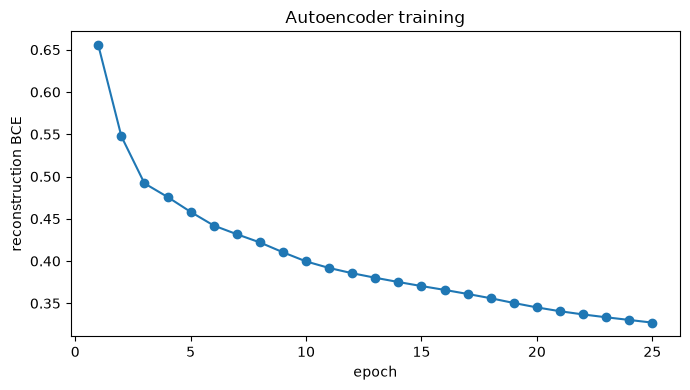

In [11]:
def train_autoencoder(model, images, epochs=25, batch_size=128, learning_rate=1e-3):
    loader = DataLoader(TensorDataset(images), batch_size=batch_size, shuffle=True)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = []

    for epoch in range(epochs):
        total_loss = 0.0
        total_images = 0
        for (batch,) in loader:
            # call autoencoder_training_step.
            batch_loss = autoencoder_training_step(model, batch, optimizer)
            # accumulate a batch-size-weighted loss and image count.
            total_loss += batch_loss * batch.shape[0]
            total_images += batch.shape[0]
        mean_loss = total_loss / total_images
        history.append(mean_loss)
        if epoch == 0 or (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d}: reconstruction loss = {mean_loss:.4f}")

    return history


torch.manual_seed(SEED)
model = TinyAutoencoder().to(DEVICE)
training_history = train_autoencoder(model, train_images)

fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(np.arange(1, len(training_history) + 1), training_history, marker="o")
axis.set(title="Autoencoder training", xlabel="epoch", ylabel="reconstruction BCE")
plt.tight_layout()
plt.show()

assert training_history[-1] < training_history[0]

## 7. Inspect reconstructions

A reconstruction is conditional on an input image: encode that image and decode its code. This is different from generating a new example from a known prior distribution.

### Exercise 5 — Reconstruct evaluation examples

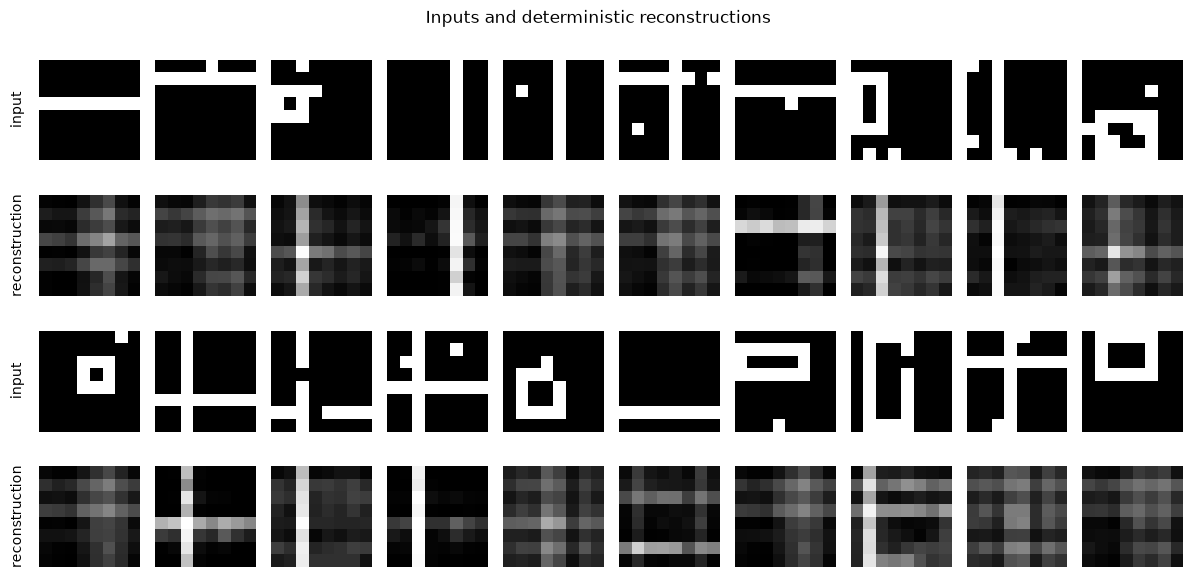

In [19]:
@torch.no_grad()
def reconstruct_images(model, images):
    model.eval()
    # move images to the model device, obtain logits, and apply sigmoid.
    return torch.sigmoid(
        model(
            images.to(
                next(model.parameters()).device
            )
        )
    )


examples = evaluation_images[:20]
reconstructions = reconstruct_images(model, examples).cpu()
assert reconstructions.shape == examples.shape
assert torch.all((reconstructions >= 0) & (reconstructions <= 1))

fig, axes = plt.subplots(4, 10, figsize=(12, 6))
for index in range(20):
    group = index // 10
    column = index % 10
    input_row = 2 * group
    reconstruction_row = input_row + 1
    axes[input_row, column].imshow(examples[index], cmap="gray", vmin=0, vmax=1)
    axes[reconstruction_row, column].imshow(
        reconstructions[index], cmap="gray", vmin=0, vmax=1
    )
    axes[input_row, column].axis("off")
    axes[reconstruction_row, column].axis("off")
for row in (0, 2):
    axes[row, 0].text(
        -0.15, 0.5, "input", transform=axes[row, 0].transAxes,
        rotation=90, va="center", ha="right",
    )
    axes[row + 1, 0].text(
        -0.15, 0.5, "reconstruction", transform=axes[row + 1, 0].transAxes,
        rotation=90, va="center", ha="right",
    )
plt.suptitle("Inputs and deterministic reconstructions")
plt.tight_layout()
plt.show()

## 8. Visualize the latent space

The model was trained without class labels, but the synthetic labels let us inspect whether similar shapes occupy nearby latent regions. Separation is not guaranteed: reconstruction only asks the code to retain enough information for the decoder.

### Exercise 6 — Encode and plot the evaluation set

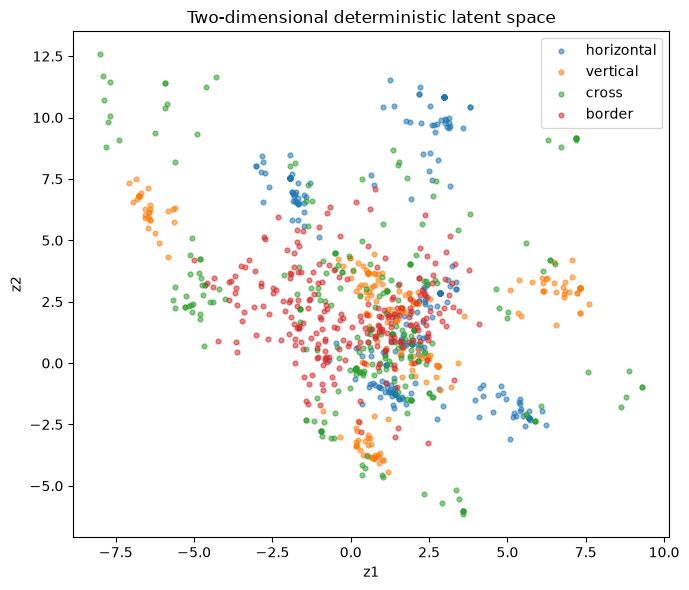

In [20]:
@torch.no_grad()
def encode_images(model, images):
    model.eval()
    # return latent codes on the CPU.
    return model.encode(
        images.to(
            next(model.parameters()).device
        )
    ).cpu()


evaluation_codes = encode_images(model, evaluation_images)
assert evaluation_codes.shape == (1000, 2)

fig, axis = plt.subplots(figsize=(7, 6))
for label, name in enumerate(SHAPE_NAMES):
    selected = evaluation_labels == label
    axis.scatter(
        evaluation_codes[selected, 0],
        evaluation_codes[selected, 1],
        s=12,
        alpha=0.55,
        label=name,
    )
axis.set(title="Two-dimensional deterministic latent space", xlabel="z1", ylabel="z2")
axis.legend()
plt.tight_layout()
plt.show()

## 9. Latent interpolation

Take two encoded examples z_a and z_b and move along the straight line between them:

$$
z(\alpha)=(1-\alpha)z_a+\alpha z_b,\qquad 0\leq\alpha\leq1.
$$

Decoding these intermediate points tests whether the learned region between two known codes changes smoothly. A smooth interpolation can be useful, but it still does not prove that every arbitrary latent point is meaningful.

### Exercise 7 — Decode an interpolation

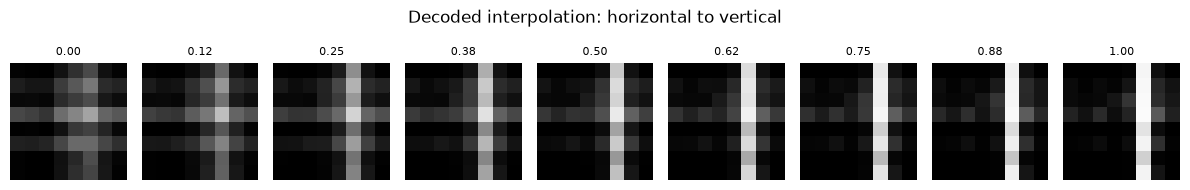

In [22]:
@torch.no_grad()
def interpolate_latent_codes(model, first_image, second_image, number_steps=9):
    model.eval()
    device = next(model.parameters()).device
    pair = torch.stack((first_image, second_image)).to(device)
    endpoints = model.encode(pair)
    alpha = torch.linspace(0, 1, number_steps, device=device).unsqueeze(1)
    # interpolate between the two endpoint codes.
    latent_codes = endpoints[0] * (1 - alpha) + endpoints[1] * alpha
    # decode, apply sigmoid, and return CPU reconstructions.
    return torch.sigmoid(model.decode(latent_codes)).cpu()


first_index = int(torch.where(evaluation_labels == 0)[0][0])
second_index = int(torch.where(evaluation_labels == 1)[0][0])
interpolations = interpolate_latent_codes(
    model,
    evaluation_images[first_index],
    evaluation_images[second_index],
)
assert interpolations.shape == (9, 8, 8)

fig, axes = plt.subplots(1, 9, figsize=(12, 2))
for step, (axis, image) in enumerate(zip(axes, interpolations)):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.set_title(f"{step / 8:.2f}", fontsize=8)
    axis.axis("off")
plt.suptitle("Decoded interpolation: horizontal to vertical")
plt.tight_layout()
plt.show()

## 10. Why this is not yet a complete generative model

The encoder tells us where training examples are placed, but the objective does not require those codes to follow a known distribution. They may occupy separated, curved, or uneven regions. Sampling z from an arbitrary distribution can therefore send the decoder to locations it never encountered during training.

The visualization below deliberately samples a broad rectangle around the observed codes. The latent-space plot shows the encoded evaluation examples, the expanded rectangle, and the regular grid points that will be decoded. The following 8×8 image panel places each decoded result in the corresponding grid location; its top row represents larger `z2` values. Some points may decode plausibly, especially near occupied regions, while others may be ambiguous or poor. The central problem is not that decoding is impossible; it is that the deterministic autoencoder has not defined a principled distribution from which new z values should be sampled.

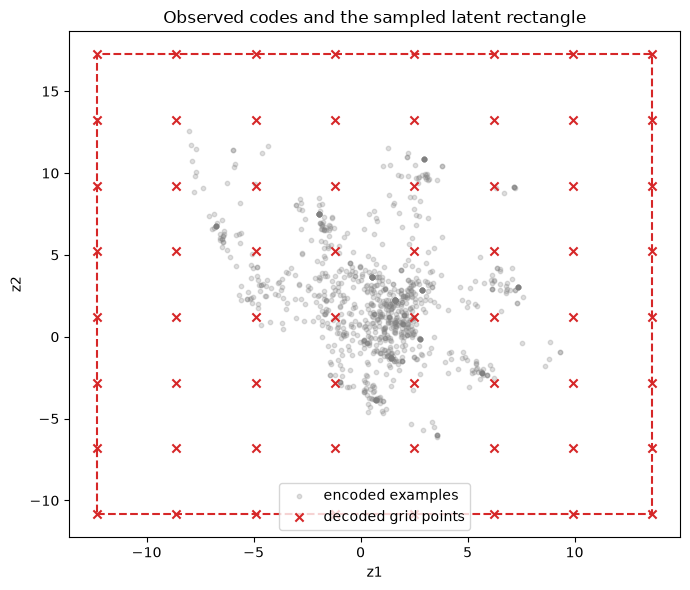

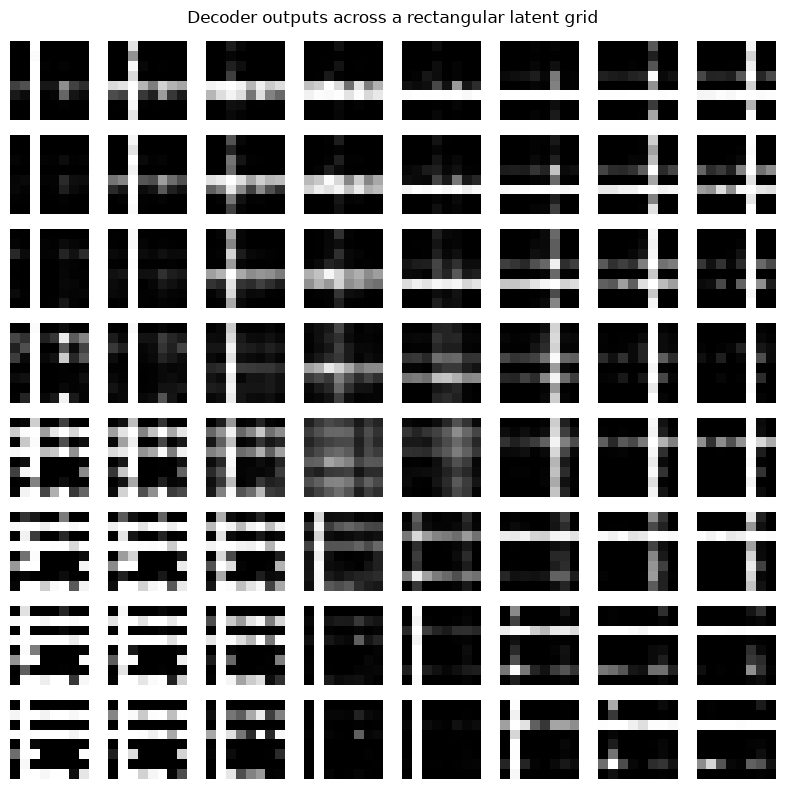

In [24]:
@torch.no_grad()
def decode_latent_grid(model, observed_codes, grid_size=8, margin=0.25):
    model.eval()
    device = next(model.parameters()).device
    minimum = observed_codes.min(dim=0).values
    maximum = observed_codes.max(dim=0).values
    span = maximum - minimum
    z1 = torch.linspace(minimum[0] - margin * span[0], maximum[0] + margin * span[0], grid_size)
    z2 = torch.linspace(minimum[1] - margin * span[1], maximum[1] + margin * span[1], grid_size)
    grid_z2, grid_z1 = torch.meshgrid(z2.flip(0), z1, indexing="ij")
    grid_codes = torch.stack((grid_z1.reshape(-1), grid_z2.reshape(-1)), dim=1)
    decoded = torch.sigmoid(model.decode(grid_codes.to(device))).cpu()
    return decoded, (z1, z2)


latent_grid_images, latent_grid_axes = decode_latent_grid(model, evaluation_codes)
z1_values, z2_values = latent_grid_axes
grid_z2, grid_z1 = torch.meshgrid(z2_values, z1_values, indexing="ij")

fig, axis = plt.subplots(figsize=(7, 6))
axis.scatter(
    evaluation_codes[:, 0], evaluation_codes[:, 1],
    s=10, alpha=0.25, color="gray", label="encoded examples",
)
axis.scatter(
    grid_z1, grid_z2, s=35, marker="x", color="tab:red",
    label="decoded grid points",
)
rectangle_z1 = [z1_values[0], z1_values[-1], z1_values[-1], z1_values[0], z1_values[0]]
rectangle_z2 = [z2_values[0], z2_values[0], z2_values[-1], z2_values[-1], z2_values[0]]
axis.plot(rectangle_z1, rectangle_z2, color="tab:red", linestyle="--")
axis.set(
    title="Observed codes and the sampled latent rectangle",
    xlabel="z1", ylabel="z2",
)
axis.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(8, 8, figsize=(8, 8))
for axis, image in zip(axes.flat, latent_grid_images):
    axis.imshow(image, cmap="gray", vmin=0, vmax=1)
    axis.axis("off")
plt.suptitle("Decoder outputs across a rectangular latent grid")
plt.tight_layout()
plt.show()

## 11. Bridge to variational autoencoders

A variational autoencoder changes two key ideas:

1. The encoder predicts a distribution q(z given x), usually represented by a mean and log-variance, instead of one fixed code.
2. A KL-divergence term encourages these encoded distributions to remain compatible with a known prior such as a standard normal distribution.

That gives us a principled generation procedure: sample z from the prior and decode it. The next notebook will derive and implement the reparameterization trick, Gaussian KL term, and ELBO objective.

## Reflection

1. What distinct roles do the encoder and decoder play?
2. Why can a small latent dimension act as an information bottleneck?
3. Why does the decoder return logits rather than sigmoid probabilities during loss calculation?
4. What does reconstruction loss encourage the latent code to preserve?
5. Why do labels appear in the latent scatter plot even though training is unsupervised?
6. What does a smooth interpolation tell us, and what does it not prove?
7. Why is sampling arbitrary latent points unreliable for a deterministic autoencoder?
8. What additional structure will a VAE impose on the latent space?

### Answers

1. The encoder compresses an image $x$ into a latent code $z$. The decoder maps $z$ back to reconstruction logits for $\hat{x}$.
2. A smaller latent representation cannot retain every input value directly, so the model must compress information useful for reconstruction.
3. The decoder returns logits because binary_cross_entropy_with_logits combines sigmoid and binary cross-entropy in one numerically stable calculation. Applying sigmoid separately can produce probabilities extremely close to zero or one and unstable logarithms.
4. Reconstruction loss encourages the latent code to preserve information the decoder needs to reconstruct the input, such as shape type, position, size, and important pixel patterns.
5. The synthetic-data generator provides labels, but the autoencoder never uses them for training. We retain them only afterward to color the latent scatter plot and inspect whether similar shapes were grouped together.
6. It suggests that the decoder behaves smoothly between these two encoded examples and that the region between them may contain meaningful representations.
7. The reconstruction objective constrains the decoder mainly at latent codes produced by the encoder. Arbitrary points may lie in unseen gaps and decode into poor or ambiguous images.
8. VAE means variational autoencoder. Unlike this deterministic autoencoder, which produces one fixed code, a VAE encoder predicts a distribution for each input—usually a mean and variance. A VAE makes the latent representation probabilistic and regularizes it toward a known prior, giving us a principled distribution from which to sample new latent codes.